# ResQNet — Sionna RT propagation paths in a dense block

Every line in this notebook is a path **Sionna RT actually traced** through the `city_damaged` mesh:
UAV → reflection / wall-crossing points → user. Nothing is drawn as a straight UAV–user line unless
Sionna found a direct line-of-sight path.

**Where:** validation window `val_a` (200 m × 200 m, centre ≈ (865, 388), ~72 % of the ground built up,
roofs up to 22 m). The flat ground near the origin used by the old demos has almost no buildings, so every
link there is line of sight. `urban_core` is the held-out final-evaluation site and is not used here.

**What is traced** (same settings as the project's 3D pipeline):

| effect | traced | why |
|---|---|---|
| direct line of sight | yes | geometry only |
| specular (smooth-surface) reflection, up to 3 bounces | yes | uses the scene material's permittivity / conductivity |
| transmission through walls (refraction) | yes | kept on to match the radio maps PPO trains on; drawn dashed |
| diffraction around edges | **no** | the whole city is one material (`itu_brick`); edge losses would rest on a guess |
| diffuse (rough-surface) scattering | **no** | the scene's scattering coefficient is 0 |

**Caveat:** the *shape* of every path comes from the geometry and is exact; how *strong* each reflection
is assumes every surface is brick (ε_r 3.91, σ 0.027 S/m at this frequency).

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd()
sys.path[:0] = [str(ROOT / "ml"), str(ROOT / "sionna")]
import obstruction as ob
import ray_viz as rv
from sionna_feedback_engine import safe_load_scene_robust

FREQ_HZ = 2.412e9          # ns-3 Wi-Fi channel 1: the frequency the whole 3D pipeline uses
UAV_ALT_M = 40.0           # start altitude of the closed-loop controller
NUM_USERS = 10             # fewer than the 30 used in evaluation, so individual paths stay readable

# UAV positions: None = the closed-loop start formation (hand-placed, NOT a PPO decision);
# a JSON file with {"uav_positions": [[x, y, z], ...]} = that placement.
POSITIONS_FILE = "data/ppo3d_val_a_positions.json"   # trained PPO (multi_lat_20261019_d, 520k), final closed-loop placement

jitc_llvm_init(): LLVM API initialization failed ..


## 1. Scene, street-level users and UAVs

In [2]:
cfg = json.loads((ROOT / "configs" / "eval_val_a_3d.json").read_text())
site, exp = cfg["scenarios"]["val_a"], cfg["experiment"]

scene = rv.configure_scene(safe_load_scene_robust("city_damaged.xml"), FREQ_HZ)
# users on open ground only (ray casts on the real mesh: nothing above 0.5 m within 3 m of the user)
users = ob.street_level_users(scene.mi_scene, site["user_region"], NUM_USERS, exp["user_seed_base"])

if POSITIONS_FILE:
    uavs = json.loads(Path(POSITIONS_FILE).read_text())["uav_positions"]
    placement = "trained PPO, final closed-loop placement" if "ppo" in POSITIONS_FILE else f"from {POSITIONS_FILE}"
else:
    spots = ob.roof_clear_uav_xy(scene.mi_scene, site["centre"], exp["uav_offsets_m"])
    uavs = [[s["x"], s["y"], UAV_ALT_M] for s in spots]
    placement = "closed-loop start formation (hand-placed, not PPO)"

print("radio material(s):", {n: type(m).__name__ for n, m in scene.radio_materials.items()})
print("UAV placement:", placement)
for k, p in enumerate(uavs):
    print(f"  UAV {k+1}: {p}")
print(f"{len(users)} street-level users in {site['user_region']}")

radio material(s): {'itu_brick': 'ITURadioMaterial'}
UAV placement: trained PPO, final closed-loop placement
  UAV 1: [909.61, 423.13, 20.0]
  UAV 2: [914.61, 378.13, 40.0]
  UAV 3: [894.61, 298.13, 20.0]
10 street-level users in {'x': [774.613037109375, 954.613037109375], 'y': [298.12890625, 478.12890625]}


## 2. Trace the paths

In [3]:
rv.place_devices(scene, uavs, users)
paths = rv.trace(scene)
rays = rv.extract_rays(paths, uavs, users)

counts = pd.Series([r["kind"] for r in rays]).value_counts().reindex(rv.KINDS, fill_value=0)
counts.index = [rv.KIND_LABEL[k] for k in counts.index]
print(f"{len(rays)} traced paths for {len(uavs)} UAVs x {len(users)} users")
counts.to_frame("paths")

112 traced paths for 3 UAVs x 10 users


,paths
Direct line of sight,12
1 reflection,22
2-3 reflections,34
Through a wall,44


## 3. Interactive 3D view

Drag to rotate, scroll to zoom. Click a legend entry to hide / show a path kind; the buttons show one
UAV's paths at a time. Hover a path for its gain and delay. Orange dots are reflection points on walls
and the ground.

In [4]:
obj = ROOT / "sionna" / "scenes" / "city_damaged.obj"
mesh_vf = rv.crop_mesh(obj, site["uav_region"]["x"], site["uav_region"]["y"], margin=30.0)
print(f"cropped mesh: {len(mesh_vf[1])} faces (full scene: 317,948)")
fig = rv.plotly_figure(rays, uavs, users, mesh_vf,
                       f"Sionna RT paths in val_a — UAVs: {placement}")
fig.show()

cropped mesh: 3951 faces (full scene: 317,948)


## 4. Sionna's own rendering

The same paths drawn by Sionna's renderer (red spheres: UAVs, dark spheres: users). Sionna colours paths
with its own scheme, not the legend of the interactive view above. Unlike the live viewer
(`scene.preview`), this image is saved inside the notebook, so it also shows on GitHub.

saved data\sionna_rays_val_a.png


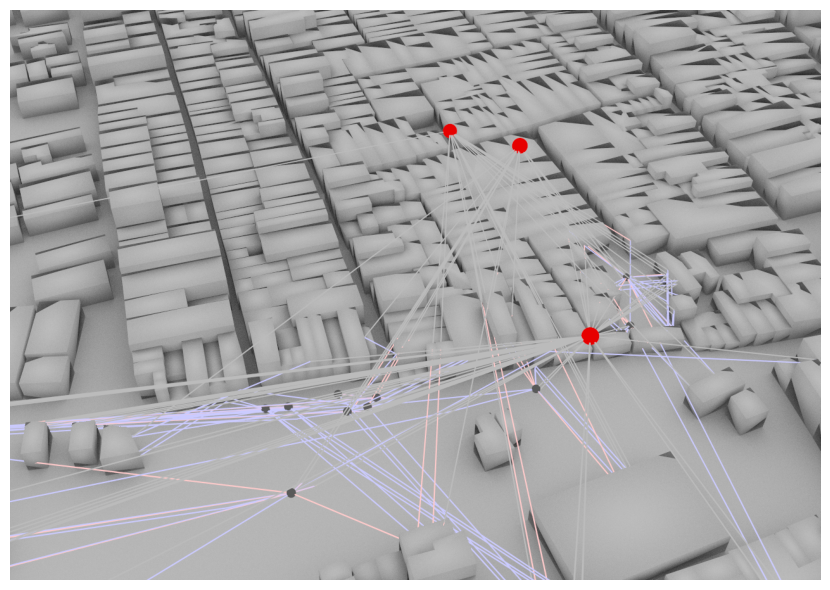

In [5]:
out_png = ROOT / "data" / "sionna_rays_val_a.png"
_ = rv.sionna_render(scene, paths, site["centre"], out_png, points=uavs + users)
print("saved", out_png.relative_to(ROOT))

## 5. Per-link breakdown

Received power uses the project's 30 dBm transmit power and the total gain of all traced paths of that
link (Sionna only, no ns-3 link model).

In [6]:
table = pd.DataFrame(rv.link_table(rays, len(uavs), len(users)))
table = table.rename(columns={k: rv.KIND_LABEL[k] for k in rv.KINDS})
best = table.loc[table.groupby("user")["rss_dbm"].idxmax()]          # strongest UAV for each user
print("Best UAV per user:")
best[["user", "uav", "rss_dbm", "strongest"] + [rv.KIND_LABEL[k] for k in rv.KINDS]].reset_index(drop=True)

Best UAV per user:


,user,uav,rss_dbm,strongest,Direct line of sight,1 reflection,2-3 reflections,Through a wall
0,1,3,-40.9,Direct line of sight,1,0,2,4
1,2,3,-47.4,Direct line of sight,1,2,2,2
2,3,3,-45.4,Direct line of sight,1,2,3,1
3,4,2,-46.4,Direct line of sight,1,1,0,1
4,5,3,-50.1,Direct line of sight,1,3,3,3
5,6,3,-50.2,Direct line of sight,1,3,4,1
6,7,3,-38.5,Direct line of sight,1,1,2,1
7,8,3,-45.9,Direct line of sight,1,3,2,2
8,9,3,-48.6,Direct line of sight,1,1,0,1
9,10,3,-49.6,Direct line of sight,1,3,3,2


In [7]:
blocked = int((best[rv.KIND_LABEL["los"]] == 0).sum())
print(f"{blocked} of {len(users)} users have no direct line of sight to their best UAV"
      + (" (reached only by reflections or through walls)." if blocked else "."))

0 of 10 users have no direct line of sight to their best UAV.


## 6. Optional: live Sionna viewer

Interactive, but it is a widget: it does not survive saving the notebook. `clip_at` cuts the scene above
the given height so the paths between buildings are visible.

In [8]:
# scene.preview(paths=paths, clip_at=30.0, resolution=(1100, 800))